# Proyecto: Campeonato Mundial de F1 - 02. Análisis y visualizaciones

### Maestria en Inteligencia Artificial Aplicada UCSM - UTPL

### Curso: Herramientas para Inteligencia Artificial

### Github:
https://github.com/vchirinosb/f1-championship

### Plataformas utilizadas:
- Jupyter Lab
- Kaggle (origen del dataset)
- SQLite

### Librerias utilizadas
- pandas==3.1.1
- numpy==2.5.5
- sqlalchemy==2.1.9
- matplotlib==3.11.2
- bokeh==3.10.2
- playwright==1.65.2

Este es el notebook principal del proyecto. Lee las dos fuentes de datos con Pandas (la base de datos SQLite construida
en el notebook 01 y los CSV `lap_times` y `pit_stops`), analiza sus columnas, limpia e integra los datos, presenta las
visualizaciones y exporta el **dataset final** que usan los notebooks de clustering y clasificación.

## Preparación del entorno

El código compartido está en `src/f1`: `data` (lectura de las fuentes), `features` (columnas derivadas y variables
pre-carrera) y `plots` (exportación de gráficos).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bokeh.io import output_notebook
from bokeh.layouts import gridplot
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.palettes import Category10
from bokeh.plotting import figure

from f1 import data, features, plots
from f1.config import FINAL_DATA_DIR, RAW_DATA_DIR
from f1.db import get_engine

`plots.render` muestra un gráfico de Bokeh o de Matplotlib y lo guarda como PNG en `images/`, igual que en el proyecto
de
Steam. `INTERACTIVE = False` muestra la imagen PNG (visible en GitHub y en la wiki); `INTERACTIVE = True` muestra los
gráficos de Bokeh interactivos.

In [3]:
plots.INTERACTIVE = False
output_notebook(hide_banner=True)

## Lectura de datos con Pandas

Leemos las dos fuentes directamente con Pandas:

* **Base de datos**: `pd.read_sql` con la conexión de solo lectura de SQLAlchemy. Leemos la vista `v_race_results` (el
  resultado de cada piloto en cada carrera, ya unido con carrera, circuito, piloto, escudería y estado), y las tablas
  `qualifying` y `driver_standings`.
* **CSV**: `pd.read_csv` para `lap_times.csv` y `pit_stops.csv`. En el CSV original los nulos aparecen como `\N`, por
  eso
  se indican en `na_values`, y los nombres de columna se pasan a snake_case con `data.convert_to_snake_case`.

### Base de datos

In [4]:
with get_engine().connect() as connection:
    race_results = pd.read_sql("SELECT * FROM v_race_results", connection)
    qualifying = pd.read_sql("SELECT * FROM qualifying", connection)
    driver_standings = pd.read_sql(
        """
        SELECT ds.*, ra.year, ra.round
        FROM driver_standings AS ds
        JOIN races AS ra ON ra.race_id = ds.race_id
        """,
        connection,
    )
race_results.shape, qualifying.shape, driver_standings.shape

((26759, 28), (10494, 9), (34863, 9))

In [5]:
race_results.head()

,race_id,year,round,race_name,race_date,circuit_id,circuit_ref,circuit_name,location,country,...,position,position_text,position_order,points,laps,time,milliseconds,fastest_lap_rank,fastest_lap_time,status
0,18,2008,1,Australian Grand Prix,2008-03-16,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,...,1.0,1,1,10.0,58,1:34:50.616,5690616.0,2.0,1:27.452,Finished
1,18,2008,1,Australian Grand Prix,2008-03-16,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,...,2.0,2,2,8.0,58,+5.478,5696094.0,3.0,1:27.739,Finished
2,18,2008,1,Australian Grand Prix,2008-03-16,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,...,3.0,3,3,6.0,58,+8.163,5698779.0,5.0,1:28.090,Finished
3,18,2008,1,Australian Grand Prix,2008-03-16,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,...,4.0,4,4,5.0,58,+17.181,5707797.0,7.0,1:28.603,Finished
4,18,2008,1,Australian Grand Prix,2008-03-16,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,...,5.0,5,5,4.0,58,+18.014,5708630.0,1.0,1:27.418,Finished


### CSV

In [6]:
def read_csv(table):
    return pd.read_csv(
        RAW_DATA_DIR / f"{table}.csv",
        na_values=["\\N"],
        keep_default_na=False,
    ).rename(columns=data.convert_to_snake_case)


lap_times = read_csv("lap_times")
pit_stops = read_csv("pit_stops")
lap_times.shape, pit_stops.shape

((589081, 6), (11371, 7))

In [7]:
lap_times.head()

,race_id,driver_id,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [8]:
pit_stops.head()

,race_id,driver_id,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


Desde la base de datos leímos 26 759 resultados (28 columnas), 10 494 filas de clasificación y 34 863 filas del
campeonato de pilotos. Desde los CSV leímos 589 081 tiempos por vuelta y 11 371 paradas en boxes. Las cinco fuentes se
relacionan por `race_id` y `driver_id`.

## Análisis de las columnas

Para cada fuente mostramos: el número de columnas y el significado de las que vamos a utilizar, los tipos de dato, los
nulos por columna, las estadísticas de las columnas numéricas, las categorías más frecuentes y los histogramas.

### Resultados de carrera (`v_race_results`, base de datos)

La vista tiene 28 columnas. Describimos a continuación solo las columnas que vamos a utilizar:

* **race_id**, **year**, **round**, **race_name**, **race_date**: identificador, temporada, número de fecha dentro de la
  temporada, nombre y fecha del Gran Premio.
* **circuit_id**, **circuit_ref**, **circuit_name**, **country**: circuito donde se corrió.
* **driver_id**, **driver_ref**, **driver_name**, **driver_nationality**: piloto.
* **constructor_id**, **constructor_ref**, **constructor_name**: escudería.
* **grid**: posición de salida; 0 significa que salió desde el pit lane o que no se registró su posición.
* **position**: posición final; nula si el piloto no fue clasificado.
* **position_order**: orden final de todos los pilotos, clasificados o no (1 = ganador). Nunca es nulo.
* **points**: puntos obtenidos con el sistema de puntos de esa temporada.
* **laps**: vueltas completadas.
* **fastest_lap_time**: tiempo de su vuelta más rápida, como texto `m:ss.mmm`.
* **status**: estado de llegada, como *Finished*, *+1 Lap* (terminó a una vuelta del ganador), *Engine* o *Accident*.

In [9]:
race_results.dtypes

race_id                 int64
year                    int64
round                   int64
race_name                 str
race_date                 str
circuit_id              int64
circuit_ref               str
circuit_name              str
location                  str
country                   str
driver_id               int64
driver_ref                str
driver_name               str
driver_nationality        str
constructor_id          int64
constructor_ref           str
constructor_name          str
grid                    int64
position              float64
position_text             str
position_order          int64
points                float64
laps                    int64
time                      str
milliseconds          float64
fastest_lap_rank      float64
fastest_lap_time          str
status                    str
dtype: object

**Nulos por columna**

In [10]:
race_results.isna().sum()[lambda nulls: nulls > 0]

position            10953
time                19079
milliseconds        19079
fastest_lap_rank    18249
fastest_lap_time    18507
dtype: int64

Qué significa cada nulo:

* **position** (10 953): el piloto no fue clasificado, casi siempre porque abandonó. Por eso usamos `position_order`,
  que ordena a todos los pilotos.
* **time** / **milliseconds** (19 079): solo tienen valor el ganador (tiempo total) y los pilotos que terminaron en la
  misma vuelta que él (diferencia). Quien terminó a vueltas o abandonó no tiene tiempo.
* **fastest_lap_rank** / **fastest_lap_time** (≈ 18 300): la vuelta más rápida de cada piloto se registra desde 2004.

**Estadísticas de las columnas numéricas**

In [11]:
race_numeric = ["grid", "position", "position_order", "points", "laps"]
race_results[race_numeric].describe()

,grid,position,position_order,points,laps
count,26759.000000,15806.000000,26759.000000,26759.000000,26759.000000
mean,11.134796,8.020499,12.794051,1.987632,46.301768
std,7.202860,4.840796,7.665951,4.351209,29.496557
min,0.000000,1.000000,1.000000,0.000000,0.000000
25%,5.000000,4.000000,6.000000,0.000000,23.000000
50%,11.000000,8.000000,12.000000,0.000000,53.000000
75%,17.000000,11.000000,18.000000,2.000000,66.000000
max,34.000000,33.000000,39.000000,50.000000,200.000000


**Categorías más frecuentes**: estado de llegada, escudería, nacionalidad del piloto y país del circuito.

In [12]:
race_results["status"].value_counts().head(10)

status
Finished           7674
+1 Lap             4037
Engine             2026
+2 Laps            1613
Accident           1062
Did not qualify    1025
Collision           854
Gearbox             810
Spun off            795
+3 Laps             731
Name: count, dtype: int64

In [13]:
race_results["constructor_name"].value_counts().head(8)

constructor_name
Ferrari       2439
McLaren       1923
Williams      1676
Tyrrell        881
Team Lotus     871
Sauber         837
Red Bull       788
Renault        787
Name: count, dtype: int64

In [14]:
race_results["driver_nationality"].value_counts().head(8)

driver_nationality
British      4559
Italian      3418
French       3095
German       2430
Brazilian    1953
American     1315
Finnish      1193
Spanish       913
Name: count, dtype: int64

In [15]:
race_results["country"].value_counts().head(8)

country
Italy      2647
USA        2011
UK         1974
Germany    1926
Monaco     1664
Belgium    1597
France     1513
Spain      1438
Name: count, dtype: int64

**Histogramas**

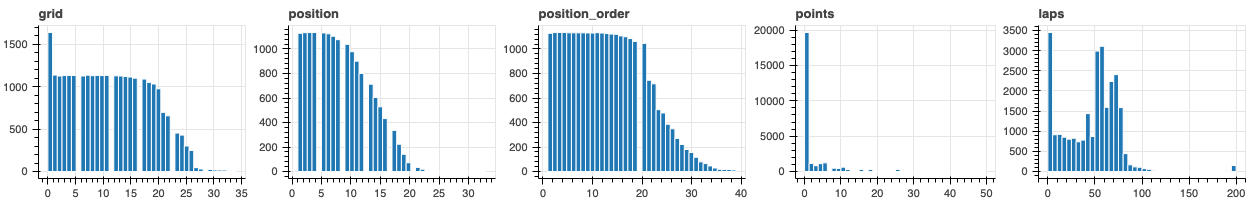

In [16]:
plots.render(
    gridplot(
        [
            plots.create_histogram(race_results[column], column)
            for column in race_numeric
        ],
        ncols=5,
    ),
    "hist_race_results",
);

* **grid** va de 0 a 34: el pico en 0 son las salidas desde el pit lane y, sobre todo, los pilotos que no se
  clasificaron para la carrera (*Did not qualify*).
* **position_order** tiene una caída después del puesto 20, que es el tamaño habitual de la parrilla.
* **points** está muy concentrado en 0: la mayoría de los pilotos no suma puntos. El máximo de 50 es Hamilton en Abu
  Dhabi 2014, la única carrera con puntos dobles.
* **laps** tiene dos grupos: los abandonos tempranos cerca de 0 y las carreras completas entre 50 y 80 vueltas. Los
  valores de 200 son las 500 Millas de Indianápolis, que contaron para el campeonato entre 1950 y 1960.
* *Finished* es el estado más frecuente (7 674), seguido de *+1 Lap* (4 037) y de las fallas de motor (2 026).
  Ferrari es la escudería con más participaciones (2 439) y los pilotos británicos los más numerosos (4 559).

### Clasificación (`qualifying`, base de datos)

La tabla tiene 9 columnas y cubre desde 1994. Columnas que vamos a utilizar:

* **race_id**, **driver_id**, **constructor_id**: carrera, piloto y escudería.
* **position**: posición en la clasificación del sábado.
* **q1**, **q2**, **q3**: tiempo de la mejor vuelta en cada sesión de clasificación, como texto `m:ss.mmm`.

In [17]:
qualifying.dtypes

qualify_id        int64
race_id           int64
driver_id         int64
constructor_id    int64
number            int64
position          int64
q1                  str
q2                  str
q3                  str
dtype: object

In [18]:
qualifying.isna().sum()

qualify_id           0
race_id              0
driver_id            0
constructor_id       0
number               0
position             0
q1                 156
q2                4647
q3                6865
dtype: int64

* **q1** (156 nulos): el piloto no marcó tiempo en la sesión.
* **q2** (4 647) y **q3** (6 865): desde 2006 la clasificación tiene tres sesiones y los más lentos quedan eliminados
  en Q1 y Q2, así que no tienen tiempo en las siguientes. Antes de 2006 había una sola sesión, guardada en `q1`.

In [19]:
qualifying[["position"]].describe()

,position
count,10494.000000
mean,11.195826
std,6.260374
min,1.000000
25%,6.000000
50%,11.000000
75%,16.000000
max,28.000000


**Categorías más frecuentes**: número de pilotos clasificados por temporada.

In [20]:
quali_years = qualifying.merge(
    race_results[["race_id", "year"]].drop_duplicates(), on="race_id"
)
quali_years["year"].value_counts().sort_index().tail(10)

year
2015    374
2016    457
2017    398
2018    420
2019    418
2020    340
2021    439
2022    440
2023    440
2024    479
Name: count, dtype: int64

Para el histograma convertimos los tiempos de texto a segundos con `features.convert_time_to_ms`.

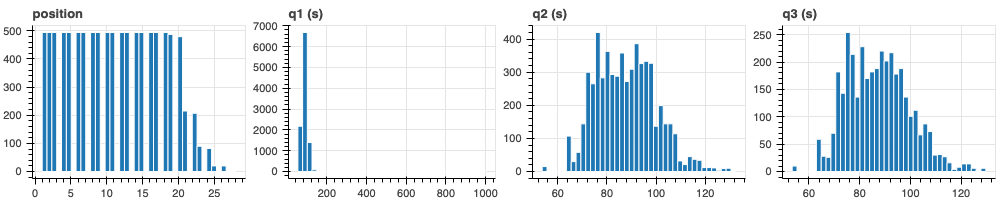

In [21]:
quali_seconds = {
    session: qualifying[session].map(features.convert_time_to_ms) / 1000
    for session in ["q1", "q2", "q3"]
}
plots.render(
    gridplot(
        [plots.create_histogram(qualifying["position"], "position")]
        + [
            plots.create_histogram(seconds, f"{session} (s)")
            for session, seconds in quali_seconds.items()
        ],
        ncols=4,
    ),
    "hist_qualifying",
);

`position` se reparte de forma uniforme entre 1 y 20 aproximadamente, como corresponde a una parrilla. Los tiempos de
Q1, Q2 y Q3 se concentran entre 70 y 110 segundos según el circuito; el histograma de Q1 se estira hacia la derecha
por un único tiempo de 16:42.640, que no es una vuelta rápida real. Como los tiempos dependen del circuito, para los
modelos usaremos solo la posición.

### Campeonato de pilotos (`driver_standings`, base de datos)

La tabla tiene 7 columnas; le agregamos `year` y `round` de la carrera. Columnas que vamos a utilizar:

* **race_id**, **driver_id**: carrera y piloto.
* **points**: puntos acumulados en el campeonato después de esa carrera.
* **position**: puesto en el campeonato después de esa carrera.
* **wins**: victorias acumuladas en la temporada.

In [22]:
driver_standings.dtypes

driver_standings_id      int64
race_id                  int64
driver_id                int64
points                 float64
position                 int64
position_text              str
wins                     int64
year                     int64
round                    int64
dtype: object

In [23]:
driver_standings.isna().sum()

driver_standings_id    0
race_id                0
driver_id              0
points                 0
position               0
position_text          0
wins                   0
year                   0
round                  0
dtype: int64

In [24]:
standings_numeric = ["points", "position", "wins"]
driver_standings[standings_numeric].describe()

,points,position,wins
count,34863.000000,34863.000000,34863.000000
mean,14.704423,19.716720,0.277343
std,38.978094,16.293401,1.032618
min,0.000000,1.000000,0.000000
25%,0.000000,8.000000,0.000000
50%,1.000000,16.000000,0.000000
75%,10.000000,26.000000,0.000000
max,575.000000,108.000000,19.000000


**Categorías más frecuentes**: `position_text` tiene el puesto como texto. El único valor que no es un número es la
letra `D`, de un piloto descalificado del campeonato.

In [25]:
driver_standings.loc[
    ~driver_standings["position_text"].str.isdigit(),
    ["year", "driver_id", "points", "position", "position_text", "wins"],
]

,year,driver_id,points,position,position_text,wins
3066,1997,30,78.0,26,D,5


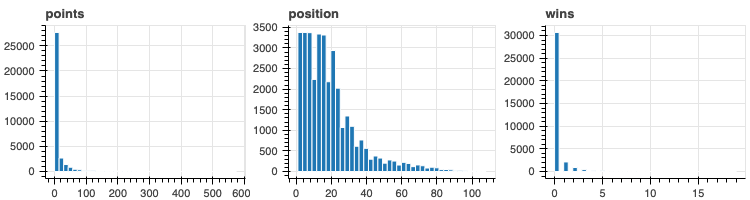

In [26]:
plots.render(
    gridplot(
        [
            plots.create_histogram(driver_standings[column], column)
            for column in standings_numeric
        ],
        ncols=3,
    ),
    "hist_driver_standings",
);

La tabla no tiene nulos. `points` está concentrado en valores bajos: llega a 575, los puntos de Verstappen en 2023, el
récord del dataset. `position` llega a 108 porque en los años 50 el campeonato incluía a todos los pilotos de las 500
Millas de Indianápolis. La única `D` es Michael Schumacher, descalificado del campeonato de 1997.

### Tiempos por vuelta (`lap_times.csv`)

El archivo tiene 6 columnas y cubre desde 1996. Columnas que vamos a utilizar:

* **race_id**, **driver_id**: carrera y piloto.
* **lap**: número de vuelta.
* **position**: posición del piloto al terminar esa vuelta.
* **milliseconds**: tiempo de la vuelta en milisegundos. La columna **time** tiene el mismo tiempo como texto.

In [27]:
lap_times.dtypes

race_id         int64
driver_id       int64
lap             int64
position        int64
time              str
milliseconds    int64
dtype: object

In [28]:
lap_times.isna().sum()

race_id         0
driver_id       0
lap             0
position        0
time            0
milliseconds    0
dtype: int64

In [29]:
lap_times[["lap", "position", "milliseconds"]].describe()

,lap,position,milliseconds
count,589081.000000,589081.000000,5.890810e+05
mean,30.018104,9.661951,9.579945e+04
std,18.407126,5.528553,7.639973e+04
min,1.000000,1.000000,5.540400e+04
25%,14.000000,5.000000,8.204100e+04
50%,29.000000,9.000000,9.060800e+04
75%,44.000000,14.000000,1.019300e+05
max,87.000000,24.000000,7.507547e+06


**Categorías más frecuentes**: carreras con más vueltas registradas.

In [30]:
lap_times["race_id"].value_counts().head(5)

race_id
354    1649
870    1621
846    1604
869    1580
59     1558
Name: count, dtype: int64

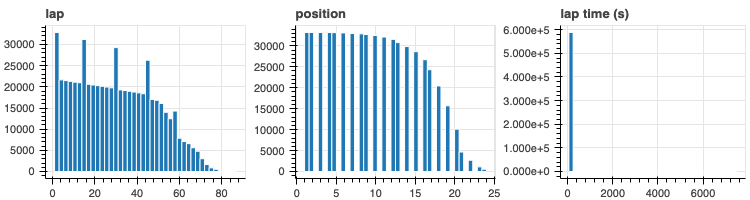

In [31]:
plots.render(
    gridplot(
        [
            plots.create_histogram(lap_times["lap"], "lap"),
            plots.create_histogram(lap_times["position"], "position"),
            plots.create_histogram(
                lap_times["milliseconds"] / 1000, "lap time (s)"
            ),
        ],
        ncols=3,
    ),
    "hist_lap_times",
);

No hay nulos. La mediana de una vuelta es de 90.6 segundos, pero el máximo es de 7 507 segundos (más de dos horas): es
la vuelta 25 del GP de Canadá 2011, detenida por una bandera roja por lluvia. Por esos valores el histograma de
tiempos se ve como una sola barra. La columna `time` repite el tiempo como texto.

### Paradas en boxes (`pit_stops.csv`)

El archivo tiene 7 columnas y cubre desde 2011. Columnas que vamos a utilizar:

* **race_id**, **driver_id**: carrera y piloto.
* **stop**: número de parada del piloto en esa carrera (1, 2, ...).
* **lap**: vuelta en la que paró.
* **milliseconds**: tiempo total en el pit lane, desde que entra hasta que sale, en milisegundos. La columna
  **duration** tiene el mismo valor en segundos como texto.

In [32]:
pit_stops.dtypes

race_id         int64
driver_id       int64
stop            int64
lap             int64
time              str
duration          str
milliseconds    int64
dtype: object

In [33]:
pit_stops.isna().sum()

race_id         0
driver_id       0
stop            0
lap             0
time            0
duration        0
milliseconds    0
dtype: int64

In [34]:
pit_stops[["stop", "lap", "milliseconds"]].describe()

,stop,lap,milliseconds
count,11371.000000,11371.000000,1.137100e+04
mean,1.787969,25.387389,8.523050e+04
std,1.521462,14.831497,3.104273e+05
min,1.000000,1.000000,1.289700e+04
25%,1.000000,13.000000,2.193750e+04
50%,2.000000,25.000000,2.360600e+04
75%,2.000000,36.000000,2.654400e+04
max,70.000000,78.000000,3.069017e+06


**Categorías más frecuentes**: número de paradas por piloto en una carrera (contando filas) y los valores más altos de
la columna `stop`.

In [35]:
pit_stops.groupby(["race_id", "driver_id"]).size().value_counts()

2    2225
1    1854
3    1069
4     307
5      91
6      26
7       3
Name: count, dtype: int64

In [36]:
pit_stops.nlargest(5, "stop")

,race_id,driver_id,stop,lap,time,duration,milliseconds
10857,1128,855,70,2,17:19:04,24.367,24367
10856,1128,858,57,2,17:01:43,24.384,24384
10855,1128,830,52,2,16:53:26,23.813,23813
10854,1128,1,51,2,16:52:10,24.232,24232
10853,1128,840,48,3,16:49:27,28.211,28211


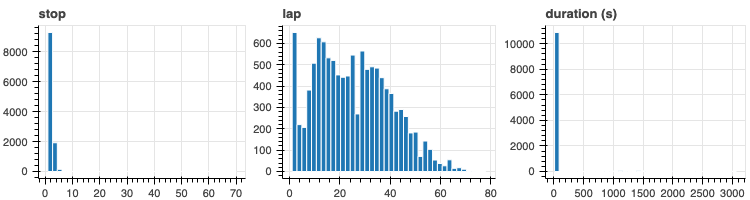

In [37]:
plots.render(
    gridplot(
        [
            plots.create_histogram(pit_stops["stop"], "stop"),
            plots.create_histogram(pit_stops["lap"], "lap"),
            plots.create_histogram(
                pit_stops["milliseconds"] / 1000, "duration (s)"
            ),
        ],
        ncols=3,
    ),
    "hist_pit_stops",
);

No hay nulos. La mediana de una parada es de 23.6 s en el pit lane, pero el máximo es de 51 minutos: son paradas con
bandera roja, en las que los coches esperan en el pit lane. Lo más común son una o dos paradas por carrera. Los valores
de `stop` de 48 a 70 son errores del dataset en Mónaco 2024 (no hubo tantas paradas); por eso contamos las paradas
como filas y no con el máximo de `stop`.

### Decisiones del análisis de columnas

**Columnas que se descartan**

* `time` y `milliseconds` de los resultados: solo existen para quienes terminaron en la vuelta del ganador.
* `time` de `lap_times` y `duration` de `pit_stops`: repiten el valor de `milliseconds` como texto.
* `time` de `pit_stops`: es la hora del día de la parada, sin valor para el análisis.
* `position_text`, `fastest_lap_rank` y `fastest_lap_time`: se usa `position_order`; la vuelta más rápida solo existe
  desde 2004.
* `q1`, `q2` y `q3`: los tiempos dependen del circuito; se usa la posición de clasificación.

**Outliers**

* Vueltas de más de dos horas y paradas de hasta 51 minutos por banderas rojas.
* Valores de `stop` erróneos en Mónaco 2024.

**Transformaciones**

* Retirar a los pilotos que no tomaron la salida (*Did not qualify*, *Withdrew*, ...), que son el pico de `grid` = 0.
* Calcular puntos con un sistema único (el de 2010) para comparar épocas, y marcar victorias, podios y carreras
  terminadas.
* Resumir `lap_times` y `pit_stops` por piloto y carrera para unirlos a los resultados.

## Preparación de los datos

### Filtrar datos confiables

Retiramos los resultados de pilotos que no tomaron la salida: *Did not qualify*, *Did not prequalify*, *Withdrew* y
*107% Rule*. No corrieron la carrera, así que no aportan a las estadísticas ni a los modelos.

In [38]:
starters = race_results[
    ~race_results["status"].isin(features.NON_STARTER_STATUSES)
].reset_index(drop=True)
len(race_results), len(starters), len(race_results) - len(starters)

(26759, 25146, 1613)

Quedan 25 146 resultados de pilotos que tomaron la salida; se retiraron 1 613 inscripciones que no llegaron a correr.

### Nuevas columnas agregadas

`features.add_result_columns` agrega columnas calculadas a partir del resultado:

* **finished**: `True` si vio la bandera a cuadros (*Finished* o *+n Laps*).
* **is_win** / **is_podium**: ganó la carrera / terminó entre los 3 primeros (`position_order` 1 / ≤ 3).
* **positions_gained**: posiciones ganadas (`grid - position_order`); nula si salió desde el pit lane.
* **points_2010**: puntos con el sistema vigente desde 2010 (25, 18, 15, 12, 10, 8, 6, 4, 2, 1), para comparar
  pilotos de distintas épocas.
* **era**: era reglamentaria de la temporada.

Además agregamos de la clasificación la posición de cada piloto (**quali_position**). Los tiempos de Q1, Q2 y Q3 no se
usan: dependen del circuito y la posición ya resume el resultado de la clasificación.

In [39]:
results = features.add_result_columns(starters)
quali = qualifying[["race_id", "driver_id", "position"]].rename(
    columns={"position": "quali_position"}
)
results = results.merge(quali, on=["race_id", "driver_id"], how="left")
results[
    ["driver_name", "grid", "position_order", "positions_gained",
     "points_2010", "quali_position", "era"]
].tail()

,driver_name,grid,position_order,positions_gained,points_2010,quali_position,era
25141,Kevin Magnussen,14,16,-2.0,0.0,15.0,2022-2024 ground effect
25142,Liam Lawson,12,17,-5.0,0.0,12.0,2022-2024 ground effect
25143,Valtteri Bottas,9,18,-9.0,0.0,9.0,2022-2024 ground effect
25144,Franco Colapinto,20,19,1.0,0.0,19.0,2022-2024 ground effect
25145,Sergio Pérez,10,20,-10.0,0.0,10.0,2022-2024 ground effect


**Estadísticas de las columnas nuevas**

In [40]:
results[["finished", "is_win", "is_podium"]].mean().round(3)

finished     0.603
is_win       0.045
is_podium    0.135
dtype: float64

In [41]:
results[["positions_gained", "points_2010", "quali_position"]].describe()

,positions_gained,points_2010,quali_position
count,25018.000000,25146.000000,10454.000000
mean,0.024342,4.514078,11.187871
std,7.181335,6.981188,6.257639
min,-31.000000,0.000000,1.000000
25%,-4.000000,0.000000,6.000000
50%,1.000000,0.000000,11.000000
75%,4.000000,8.000000,16.000000
max,30.000000,25.000000,28.000000


El 60.3 % de los pilotos que toman la salida termina la carrera, el 13.5 % sube al podio y el 4.5 % gana. Las
posiciones ganadas tienen media cercana a 0 (lo que unos ganan otros lo pierden), mediana de +1 y valores extremos de
-31 y +30. La posición de clasificación existe para 10 454 resultados (desde 1994).

### Eliminar outliers

Retiramos los valores que no representan el ritmo normal de carrera:

* **Paradas de más de 60 segundos**: la mediana es de unos 24 s. Las paradas más largas ocurren con bandera roja (los
  coches esperan en el pit lane) o por reparaciones.
* **Vueltas de más del doble de la mediana de su carrera**: corresponden a banderas rojas o a reparaciones en boxes.
  Las vueltas detrás del coche de seguridad y las de entrada y salida de boxes se mantienen, porque son parte de la
  carrera.

In [42]:
clean_pit_stops = pit_stops[pit_stops["milliseconds"] <= 60_000]
race_median = lap_times.groupby("race_id")["milliseconds"].transform("median")
clean_lap_times = lap_times[lap_times["milliseconds"] <= 2 * race_median]
pd.DataFrame(
    {
        "rows": [len(pit_stops), len(lap_times)],
        "removed": [
            len(pit_stops) - len(clean_pit_stops),
            len(lap_times) - len(clean_lap_times),
        ],
    },
    index=["pit_stops", "lap_times"],
)

,rows,removed
pit_stops,11371,517
lap_times,589081,1092


### Histogramas

Tiempos por vuelta y duración de las paradas después de retirar los outliers.

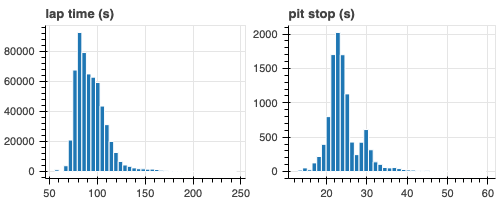

In [43]:
plots.render(
    gridplot(
        [
            plots.create_histogram(
                clean_lap_times["milliseconds"] / 1000, "lap time (s)"
            ),
            plots.create_histogram(
                clean_pit_stops["milliseconds"] / 1000, "pit stop (s)"
            ),
        ],
        ncols=2,
    ),
    "hist_clean_times",
);

Se retiraron 517 paradas (4.5 %) y 1 092 vueltas (0.2 %). Ahora los tiempos por vuelta se concentran entre 70 y 120
segundos y las paradas entre 18 y 35 segundos; la cola de la derecha de las vueltas son las vueltas detrás del coche
de seguridad y las de entrada a boxes, que forman parte de la carrera.

### Integración CSV + base de datos

Unimos cada vuelta de `lap_times.csv` con los resultados de la base de datos por carrera y piloto, para conocer su año,
circuito, piloto y escudería. Contamos las vueltas que no encuentran su resultado.

In [44]:
laps = clean_lap_times.merge(
    race_results[
        ["race_id", "driver_id", "year", "race_name", "circuit_name",
         "driver_name", "constructor_name"]
    ].drop_duplicates(["race_id", "driver_id"]),
    on=["race_id", "driver_id"],
    how="left",
    indicator=True,
)
laps["_merge"].value_counts()

_merge
both          587989
left_only          0
right_only         0
Name: count, dtype: int64

Las 587 989 vueltas encontraron su resultado (`both`): no hay vueltas sin correspondencia (`left_only` = 0). Cada vuelta
queda asociada a su carrera, año, circuito, piloto y escudería.

Para el dataset final resumimos las vueltas y las paradas por piloto y carrera:

* **median_lap_ms**: mediana de sus tiempos por vuelta.
* **pace_gap_pct**: cuánto más lenta fue su mediana que la mejor mediana de la carrera, en porcentaje (0 = el más
  rápido).
* **pit_stops** / **mean_pit_ms**: número de paradas y duración media en el pit lane.

In [45]:
lap_summary = laps.groupby(["race_id", "driver_id"], as_index=False).agg(
    median_lap_ms=("milliseconds", "median"),
)
best_median = lap_summary.groupby("race_id")["median_lap_ms"].transform("min")
lap_summary["pace_gap_pct"] = (
    100 * (lap_summary["median_lap_ms"] / best_median - 1)
).round(3)

pit_summary = clean_pit_stops.groupby(
    ["race_id", "driver_id"], as_index=False
).agg(pit_stops=("stop", "count"), mean_pit_ms=("milliseconds", "mean"))

results = results.merge(
    lap_summary, on=["race_id", "driver_id"], how="left"
).merge(pit_summary, on=["race_id", "driver_id"], how="left")

Resultados desde 1996 sin vueltas registradas y resultados desde 2011 sin paradas:

In [46]:
pd.Series(
    {
        "results since 1996": (results["year"] >= 1996).sum(),
        "without lap data": (
            (results["year"] >= 1996) & results["median_lap_ms"].isna()
        ).sum(),
        "results since 2011": (results["year"] >= 2011).sum(),
        "without pit stops": (
            (results["year"] >= 2011) & results["pit_stops"].isna()
        ).sum(),
    }
)

results since 1996    11438
without lap data        408
results since 2011     5960
without pit stops       432
dtype: int64

De los 11 438 resultados desde 1996, 408 no tienen vueltas registradas: 401 son pilotos que abandonaron sin completar
la primera vuelta. De los 5 960 resultados desde 2011, 432 no tienen paradas: 156 abandonaron en la primera vuelta y
el resto son, sobre todo, carreras con bandera roja (Bélgica 2021, Mónaco 2024), donde los neumáticos se cambiaron
durante la interrupción y esas paradas de más de 60 s se retiraron como outliers.

### Variables pre-carrera

El modelo de clasificación solo puede usar lo que se conoce **antes** de la carrera.
`features.add_pre_race_features` calcula, ordenando por fecha y con `shift(1)` para no usar el resultado de la propia
carrera:

* **driver_races_before**: carreras disputadas antes por el piloto (experiencia).
* **driver_points_before** / **driver_rank_before**: puntos y puesto del piloto en el campeonato después de la carrera
  anterior de la temporada, tomados de `driver_standings` (incluyen los puntos de las carreras sprint). En la primera
  fecha valen 0 puntos y no hay puesto.
* **driver_form**: posición final media del piloto en sus últimas 5 carreras.
* **driver_circuit_form**: posición final media del piloto en ese circuito en visitas anteriores.
* **constructor_form**: posición final media de la escudería en sus últimas 5 carreras.

La prueba `tests/test_features.py` comprueba que cambiar el resultado de una carrera no cambia estas variables.

In [47]:
results = features.add_pre_race_features(results, driver_standings)
results.loc[
    results["race_name"].eq("Abu Dhabi Grand Prix") & results["year"].eq(2021),
    [
        "driver_name", "grid", "driver_points_before", "driver_rank_before",
        "driver_form", "constructor_form", "position_order"
    ],
].head(5)

,driver_name,grid,driver_points_before,driver_rank_before,driver_form,constructor_form,position_order
23772,Max Verstappen,1,369.5,1.0,1.6,3.9,1
23773,Lewis Hamilton,2,369.5,2.0,1.4,5.4,2
23774,Carlos Sainz,5,149.5,7.0,6.8,6.3,3
23775,Yuki Tsunoda,8,20.0,14.0,14.2,11.9,4
23776,Pierre Gasly,12,100.0,9.0,9.6,11.9,5


Antes de la última carrera de 2021 Verstappen y Hamilton llegaban empatados con 369.5 puntos (Verstappen primero por
tener más victorias). Hamilton tenía mejor forma reciente (1.4 frente a 1.6 de posición media) y Verstappen la mejor
escudería en las últimas carreras (3.9). Ninguna de estas variables usa el resultado de esa carrera.

## Visualizaciones

Seis gráficos: cuatro con datos de la base de datos, uno con los CSV y uno que combina ambas fuentes. Los gráficos de
Matplotlib son estáticos; los de Bokeh tienen `HoverTool` cuando `INTERACTIVE = True`.

### Victorias por escudería y década (Matplotlib, base de datos)

Contamos las victorias de las 10 escuderías más ganadoras en cada década. Las tres carreras con dos ganadores
(coche compartido) se cuentan una sola vez.

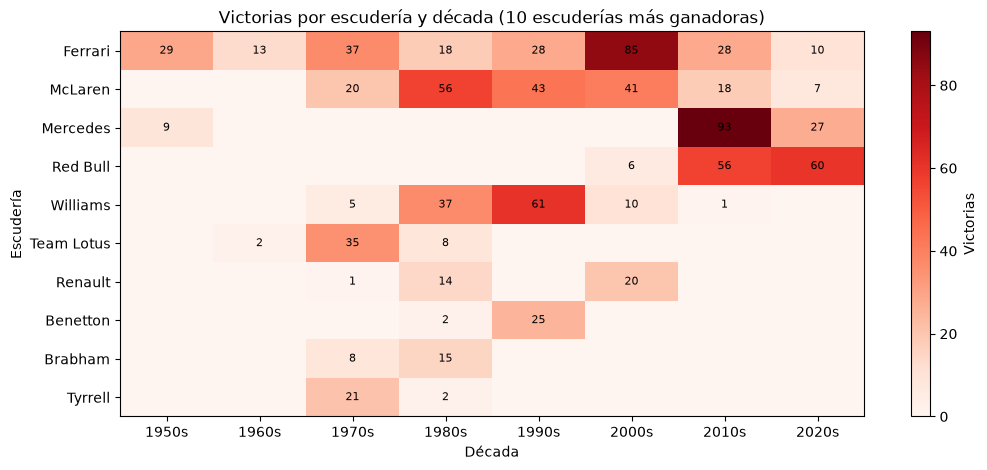

In [48]:
winners = data.read_sql(
    "SELECT race_id, year, constructor_name FROM v_race_winners"
).drop_duplicates("race_id")
winners["decade"] = winners["year"] // 10 * 10
top_constructors = winners["constructor_name"].value_counts().head(10).index
wins = pd.crosstab(
    winners["constructor_name"], winners["decade"]
).loc[top_constructors]

fig, ax = plt.subplots(figsize=(12, 5))
image = ax.imshow(wins, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(wins.columns)), [f"{d}s" for d in wins.columns])
ax.set_yticks(range(len(wins.index)), wins.index)
for (row, column), value in np.ndenumerate(wins.to_numpy()):
    if value:
        ax.text(column, row, value, ha="center", va="center", fontsize=8)

ax.set_title("Victorias por escudería y década (10 escuderías más ganadoras)")
ax.set_xlabel("Década")
ax.set_ylabel("Escudería")
fig.colorbar(image, ax=ax, label="Victorias")
plots.render(fig, "wins_by_constructor_decade");

Cada década tiene una escudería dominante: Lotus en los 70 (35 victorias), McLaren en los 80 (56), Williams en los 90
(61), Ferrari en los 2000 (85, la etapa de Schumacher), Mercedes en los 2010 (93, la era híbrida) y Red Bull en los
2020 (60). Ferrari es la única escudería que ganó en todas las décadas.

### Mapa de circuitos (Matplotlib, base de datos)

Cada punto es un circuito ubicado por su latitud y longitud; el tamaño indica cuántos Grandes Premios se corrieron allí
y el color, el año del primero. El panel derecho amplía Europa, donde están la mayoría de los circuitos.

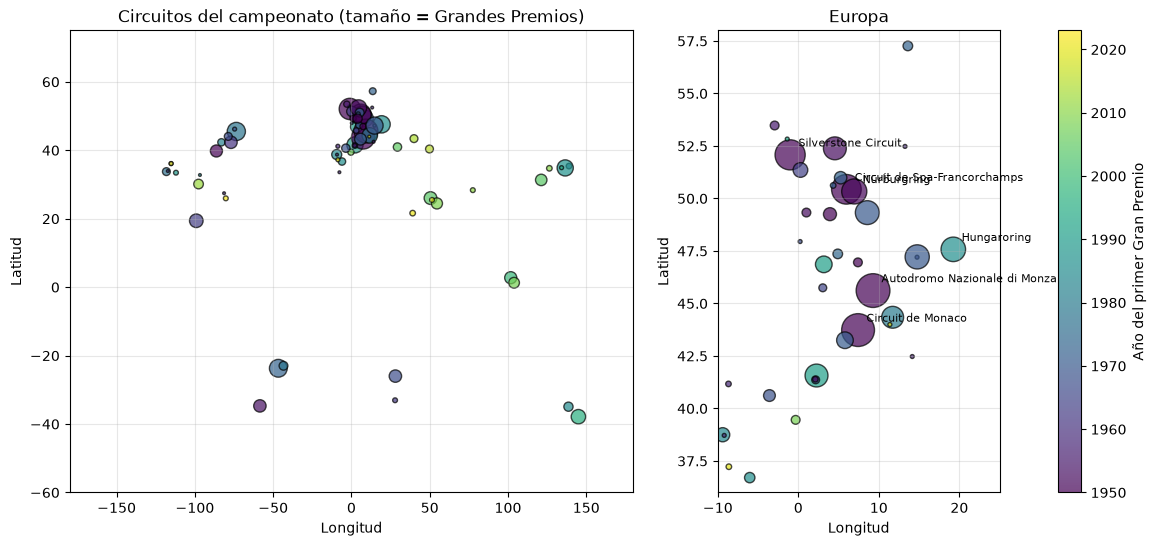

In [49]:
circuits = data.read_sql(
    """
    SELECT ci.name AS circuit_name, ci.country, ci.lat, ci.lng,
           COUNT(*) AS races, MIN(ra.year) AS first_year
    FROM circuits AS ci
    JOIN races AS ra ON ra.circuit_id = ci.circuit_id
    GROUP BY ci.circuit_id
    """
)
EUROPE = {"xlim": (-10, 25), "ylim": (36, 58)}
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]}
)
for ax, limits, size in zip(
    axes, [{"xlim": (-180, 180), "ylim": (-60, 75)}, EUROPE], [4, 8]
):
    points = ax.scatter(
        circuits["lng"], circuits["lat"], s=circuits["races"] * size,
        c=circuits["first_year"], cmap="viridis", alpha=0.7,
        edgecolor="black",
    )
    ax.set(**limits, xlabel="Longitud", ylabel="Latitud")
    ax.grid(alpha=0.3)

in_europe = circuits["lng"].between(*EUROPE["xlim"]) & circuits[
    "lat"
].between(*EUROPE["ylim"])
for _, circuit in circuits[in_europe].nlargest(6, "races").iterrows():
    axes[1].annotate(
        circuit["circuit_name"], (circuit["lng"], circuit["lat"]),
        xytext=(6, 6), textcoords="offset points", fontsize=8,
    )

axes[0].set_title("Circuitos del campeonato (tamaño = Grandes Premios)")
axes[1].set_title("Europa")
fig.colorbar(points, ax=axes, label="Año del primer Gran Premio")
plots.render(fig, "circuits_map");

In [50]:
circuits.nlargest(5, "races")[["circuit_name", "country", "races"]]

,circuit_name,country,races
13,Autodromo Nazionale di Monza,Italy,74
5,Circuit de Monaco,Monaco,70
8,Silverstone Circuit,UK,59
12,Circuit de Spa-Francorchamps,Belgium,57
6,Circuit Gilles Villeneuve,Canada,43


El campeonato nació en Europa: los circuitos más antiguos (morados) y con más carreras están allí, con Monza (74
Grandes Premios), Mónaco (70), Silverstone (59) y Spa-Francorchamps (57) a la cabeza. Los circuitos nuevos (verdes y
amarillos) están en Asia, Medio Oriente y América, lo que muestra la expansión del calendario desde los años 2000.

### Evolución del campeonato 2021 (Bokeh, base de datos)

Puntos acumulados después de cada carrera por los cuatro primeros del campeonato de pilotos 2021.

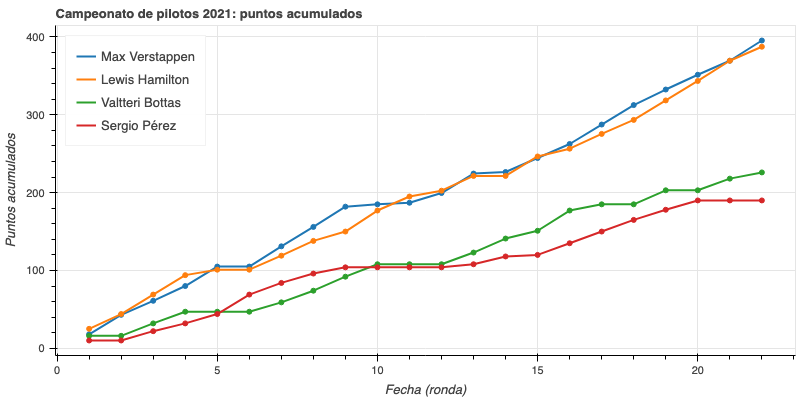

In [51]:
standings_2021 = data.read_sql(
    """
    SELECT ra.round, ra.name AS race_name,
           d.forename || ' ' || d.surname AS driver_name, ds.points
    FROM driver_standings AS ds
    JOIN races AS ra ON ra.race_id = ds.race_id
    JOIN drivers AS d ON d.driver_id = ds.driver_id
    WHERE ra.year = :year
    ORDER BY ra.round
    """,
    {"year": 2021},
)
last_round = standings_2021[
    standings_2021["round"] == standings_2021["round"].max()
]
top_drivers = last_round.nlargest(4, "points")["driver_name"]

chart = figure(
    title="Campeonato de pilotos 2021: puntos acumulados",
    width=800, height=400,
    x_axis_label="Fecha (ronda)", y_axis_label="Puntos acumulados",
)
for driver, color in zip(top_drivers, Category10[4]):
    source = ColumnDataSource(
        standings_2021[standings_2021["driver_name"] == driver]
    )
    chart.line(
        "round", "points", source=source, color=color,
        line_width=2, legend_label=driver
    )
    chart.scatter("round", "points", source=source, color=color, size=5)

chart.add_tools(
    HoverTool(
        tooltips=[
            ("Piloto", "@driver_name"), ("Carrera", "@race_name"),
            ("Puntos", "@points"),
        ]
    )
)
chart.legend.location = "top_left"
plots.render(chart, "championship_2021");

In [52]:
last_round.nlargest(4, "points")[["driver_name", "points"]]

,driver_name,points
430,Max Verstappen,395.5
429,Lewis Hamilton,387.5
431,Valtteri Bottas,226.0
433,Sergio Pérez,190.0


El campeonato 2021 fue uno de los más disputados: Verstappen y Hamilton se alternaron el liderato durante toda la
temporada y llegaron empatados a la última carrera. Verstappen terminó con 395.5 puntos frente a 387.5 de Hamilton.
Bottas (226) y Pérez (190) quedaron muy lejos.

### Ritmo vuelta a vuelta: Abu Dhabi 2021 (Bokeh, CSV + base de datos)

Tiempos por vuelta de `lap_times.csv`, ya unidos con los nombres de pilotos y carreras de la base de datos, para
Verstappen y Hamilton en la última carrera de 2021.

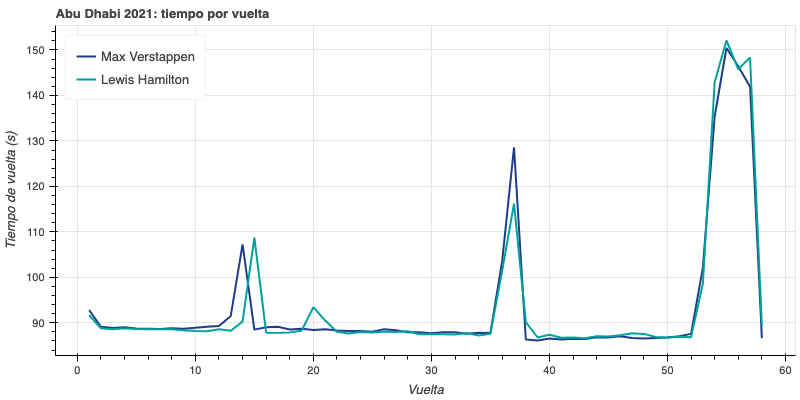

In [53]:
abu_dhabi = laps[
    (laps["year"] == 2021) & (laps["race_name"] == "Abu Dhabi Grand Prix")
    & laps["driver_name"].isin(["Max Verstappen", "Lewis Hamilton"])
].copy()
abu_dhabi["seconds"] = abu_dhabi["milliseconds"] / 1000

chart = figure(
    title="Abu Dhabi 2021: tiempo por vuelta", width=800, height=400,
    x_axis_label="Vuelta", y_axis_label="Tiempo de vuelta (s)",
)
for (driver, color) in zip(
    ["Max Verstappen", "Lewis Hamilton"], ["#1f3c88", "#00a19b"]
):
    source = ColumnDataSource(abu_dhabi[abu_dhabi["driver_name"] == driver])
    chart.line(
        "lap", "seconds", source=source, color=color, line_width=2,
        legend_label=driver
    )

chart.add_tools(
    HoverTool(
        tooltips=[
            ("Piloto", "@driver_name"), ("Vuelta", "@lap"),
            ("Tiempo (s)", "@seconds"), ("Posición", "@position"),
        ]
    )
)
chart.legend.location = "top_left"
plots.render(chart, "pace_abu_dhabi_2021");

In [54]:
abu_dhabi.pivot(index="lap", columns="driver_name", values="seconds").agg(
    ["median", "min", "max"]
).round(3)

driver_name,Lewis Hamilton,Max Verstappen
median,88.042,88.368
min,86.615,86.103
max,152.083,150.435


Durante casi toda la carrera los dos pilotos giraron con un ritmo muy similar, alrededor de 88 segundos (Hamilton con
una mediana algo menor: 88.0 s frente a 88.4 s). Los picos son las paradas en boxes (vueltas 14 y 15), un coche de
seguridad virtual (vuelta 37) y el coche de seguridad de las vueltas 53 a 57. Verstappen paró a cambiar neumáticos con
el coche de seguridad, marcó la vuelta más rápida de los dos (86.1 s) y adelantó a Hamilton en la última vuelta.

### Duración de las paradas por año (Matplotlib, CSV)

Distribución del tiempo en el pit lane por temporada, desde 2011, sin las paradas de más de 60 s.

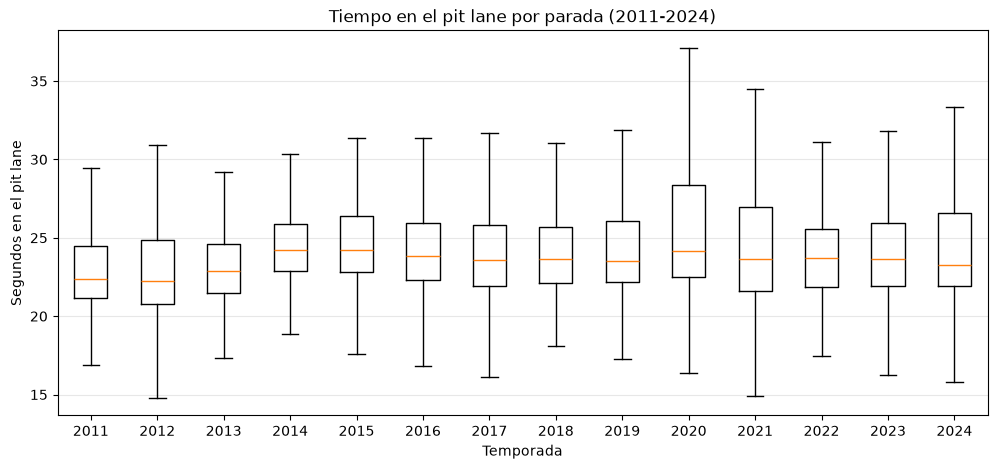

In [55]:
pit_years = clean_pit_stops.merge(
    race_results[["race_id", "year"]].drop_duplicates(), on="race_id"
)
years = sorted(pit_years["year"].unique())
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(
    [pit_years.loc[pit_years["year"] == year, "milliseconds"] / 1000
     for year in years],
    tick_labels=years, showfliers=False,
)
ax.set_title("Tiempo en el pit lane por parada (2011-2024)")
ax.set_xlabel("Temporada")
ax.set_ylabel("Segundos en el pit lane")
ax.grid(axis="y", alpha=0.3)
plots.render(fig, "pit_stop_duration_by_year");

In [56]:
(pit_years.groupby("year")["milliseconds"].median() / 1000).round(2)

year
2011    22.37
2012    22.26
2013    22.87
2014    24.22
2015    24.25
2016    23.82
2017    23.58
2018    23.65
2019    23.52
2020    24.17
2021    23.65
2022    23.69
2023    23.67
2024    23.29
Name: milliseconds, dtype: float64

La mediana del tiempo en el pit lane se mantuvo entre 22 y 24 segundos durante 14 temporadas: depende sobre todo del
largo del pit lane y del límite de velocidad, no de la rapidez de los mecánicos. Subió en 2014 (24.2 s) y 2020 tuvo la
mayor dispersión, posiblemente por los circuitos poco habituales del calendario de la pandemia.

### Posición de salida vs. resultado (Matplotlib, base de datos)

Porcentaje de victorias y de podios según la posición de salida, desde 1994, para quienes salieron entre el 1.° y el
20.° lugar.

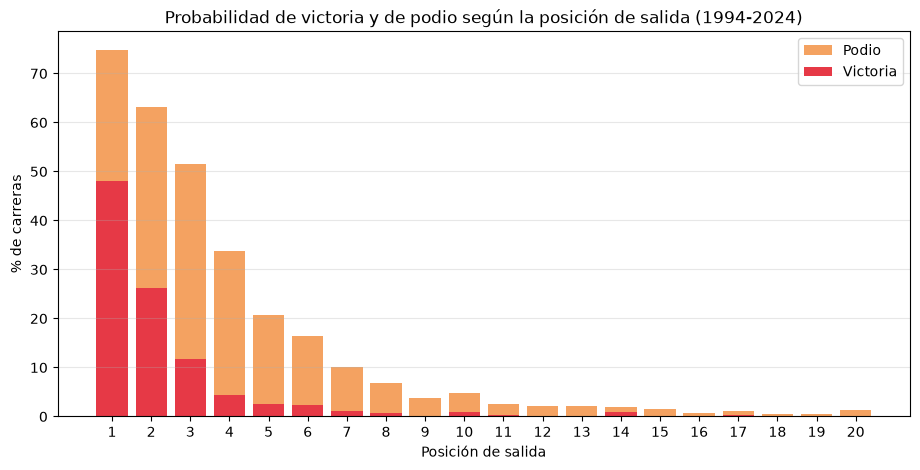

In [57]:
modern = results[(results["year"] >= 1994) & results["grid"].between(1, 20)]
by_grid = modern.groupby("grid")[["is_win", "is_podium"]].mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(
    by_grid.index, by_grid["is_podium"], color="#f4a261",
    label="Podio"
)
ax.bar(by_grid.index, by_grid["is_win"], color="#e63946", label="Victoria")
ax.set_xticks(by_grid.index)
ax.set_title(
    "Probabilidad de victoria y de podio según la posición de salida"
    " (1994-2024)"
)
ax.set_xlabel("Posición de salida")
ax.set_ylabel("% de carreras")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plots.render(fig, "grid_vs_result");

In [58]:
by_grid.head(5).round(1)

,is_win,is_podium
grid,,
1,48.1,74.8
2,26.1,63.1
3,11.8,51.6
4,4.3,33.7
5,2.6,20.6


Salir primero es la mayor ventaja: desde 1994 quien sale desde la pole gana el 48.1 % de las carreras y sube al podio
en el 74.8 %. Desde la segunda posición la probabilidad de ganar baja a 26.1 % y desde la quinta a 2.6 %. Desde más
atrás del 10.° lugar, ganar es excepcional. Por eso `grid` y `quali_position` serán variables importantes en el
modelo de clasificación.

## Dataset final

Una fila por piloto y carrera (solo pilotos que tomaron la salida, 1950-2024), con las variables que usan los modelos.
Las columnas de resultado (posición, puntos, podio, ritmo y paradas) describen la carrera ya disputada: sirven como
variable objetivo o para el clustering, nunca como entrada del modelo de clasificación.

In [59]:
dictionary = pd.DataFrame(
    [
        ("race_id", "Identificador de la carrera"),
        ("year", "Temporada"),
        ("round", "Número de fecha dentro de la temporada"),
        ("race_date", "Fecha de la carrera (AAAA-MM-DD)"),
        ("race_name", "Nombre del Gran Premio"),
        ("era", "Era reglamentaria"),
        ("circuit_id", "Identificador del circuito"),
        ("circuit_ref", "Identificador legible del circuito, ej. monza"),
        ("circuit_name", "Nombre del circuito"),
        ("country", "País del circuito"),
        ("driver_id", "Identificador del piloto"),
        ("driver_ref", "Identificador legible del piloto, ej. hamilton"),
        ("driver_name", "Nombre del piloto"),
        ("driver_nationality", "Nacionalidad del piloto"),
        ("constructor_id", "Identificador de la escudería"),
        ("constructor_ref", "Identificador legible de la escudería"),
        ("constructor_name", "Nombre de la escudería"),
        ("grid", "Posición de salida (0 = pit lane o desconocida)"),
        ("quali_position", "Posición en la clasificación (desde 1994)"),
        ("driver_races_before", "Pre-carrera: carreras previas del piloto"),
        (
            "driver_points_before",
            "Pre-carrera: puntos del piloto en la temporada"
        ),
        (
            "driver_rank_before",
            "Pre-carrera: puesto en el campeonato (nulo en la 1.ª fecha)"
        ),
        (
            "driver_form",
            "Pre-carrera: posición media en las últimas 5 carreras"
        ),
        (
            "driver_circuit_form",
            "Pre-carrera: posición media en visitas previas al circuito"
        ),
        (
            "constructor_form",
            "Pre-carrera: posición media de la escudería, últimas 5 carreras"
        ),
        ("position", "Resultado: posición final (nula si no clasificó)"),
        ("position_order", "Resultado: orden final de todos los pilotos"),
        ("points", "Resultado: puntos con el sistema de la época"),
        ("points_2010", "Resultado: puntos con el sistema de 2010"),
        ("laps", "Resultado: vueltas completadas"),
        ("status", "Resultado: estado de llegada"),
        ("finished", "Resultado: terminó la carrera"),
        ("is_win", "Resultado: ganó la carrera"),
        ("is_podium", "Resultado: terminó entre los 3 primeros"),
        ("positions_gained", "Resultado: grid - position_order"),
        (
            "median_lap_ms",
            "CSV: mediana del tiempo por vuelta en ms (desde 1996)"
        ),
        ("pace_gap_pct", "CSV: % más lento que la mejor mediana"),
        ("pit_stops", "CSV: número de paradas (desde 2011)"),
        ("mean_pit_ms", "CSV: tiempo medio en el pit lane en ms"),
    ],
    columns=["column", "description"],
)
final = results[dictionary["column"]].sort_values(
    ["race_date", "race_id", "position_order"], ignore_index=True
)
assert not final.columns.duplicated().any()
final.shape

(25146, 39)

In [60]:
pd.set_option("display.max_colwidth", 80)
dictionary

,column,description
0,race_id,Identificador de la carrera
1,year,Temporada
2,round,Número de fecha dentro de la temporada
3,race_date,Fecha de la carrera (AAAA-MM-DD)
4,race_name,Nombre del Gran Premio
5,era,Era reglamentaria
6,circuit_id,Identificador del circuito
7,circuit_ref,"Identificador legible del circuito, ej. monza"
8,circuit_name,Nombre del circuito
9,country,País del circuito


In [61]:
FINAL_DATA_DIR.mkdir(exist_ok=True)
final_path = FINAL_DATA_DIR / "f1_dataset_final.csv"
final.to_csv(final_path, index=False)
final_path.name, round(final_path.stat().st_size / 1024 / 1024, 1)

('f1_dataset_final.csv', 6.2)

In [62]:
final.isna().mean().round(3)[lambda share: share > 0]

quali_position         0.584
driver_rank_before     0.133
driver_form            0.031
driver_circuit_form    0.301
constructor_form       0.013
position               0.372
positions_gained       0.005
median_lap_ms          0.561
pace_gap_pct           0.561
pit_stops              0.780
mean_pit_ms            0.780
dtype: float64

El dataset final tiene 25 146 filas (una por piloto y carrera, de 1950 a 2024) y 39 columnas sin duplicados. Los nulos
se explican por la cobertura de cada fuente: la clasificación existe desde 1994 (58 % nulos), las vueltas desde 1996
(56 %) y las paradas desde 2011 (78 %); `driver_circuit_form` es nula la primera vez que un piloto corre en un circuito
y `driver_rank_before`, en la primera fecha de cada temporada. El notebook de clasificación usará las
carreras desde 1994.

## Conclusiones

- Leímos con Pandas las dos fuentes: la vista `v_race_results` y las tablas `qualifying` y `driver_standings` desde la
  base de datos con `pd.read_sql`, y `lap_times.csv` y `pit_stops.csv` con `pd.read_csv`.
- El análisis de columnas explicó los nulos (pilotos no clasificados, sesiones de clasificación por eliminación,
  datos que se registran desde 2004) y encontró outliers por banderas rojas y errores del dataset (Mónaco 2024).
- Retiramos 1 613 inscripciones de pilotos que no tomaron la salida, 517 paradas y 1 092 vueltas anómalas, y unimos
  las 587 989 vueltas con los resultados de la base de datos sin ninguna fila sin correspondencia.
- Calculamos variables pre-carrera (puntos y puesto en el campeonato, forma reciente del piloto y de la escudería,
  historial en el circuito) sin fuga de información, verificado con una prueba unitaria.
- Las visualizaciones muestran que cada década tuvo una escudería dominante, que el calendario pasó de Europa al resto
  del mundo, que 2021 se decidió en la última vuelta y que la posición de salida es la variable que más se relaciona
  con el resultado: desde la pole se gana casi la mitad de las carreras.
- El dataset final `data/final/f1_dataset_final.csv` (25 146 filas y 39 columnas), documentado con el diccionario de
  columnas de este notebook, es la entrada de los notebooks de clustering y clasificación.